# Лабораторная работа № 10. Полиномиальная регрессия
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** научиться применять разработанный пайплайн для тиражирования кода с целью решения задачи полиномиальной регрессии.

**Задачи:** повторно использовать пайплайн; изучить поведение модели при изменении степени полинома; сравнить модификации kNN, указанные в задачах методички.


## 1. Локальный запуск
Используем прежнее Conda-окружение `rcaeval-ai`. В VS Code выбираем его ядро и выполняем **Run All**. В `environment.yml` добавлен UMAP; Pillow явно указан для чтения изображений. При необходимости обновляем окружение из корня:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```

Повторный запуск читает сохранённые данные. RCAEval не скачивается заново. Таблицы, координаты, результаты и рисунки сохраняются в папке этой работы внутри `reports/`.

Подключаем библиотеки для файлов, таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
from time import perf_counter
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем методы машинного обучения.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import cross_val_score, GroupKFold, StratifiedGroupKFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab10'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'umap-learn', 'Pillow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
umap-learn       0.5.12
Pillow           12.3.0
Name: Версия, dtype: object

167

Определяем функцию сохранения и показа рисунков.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Полиномиальная регрессия добавляет степени признака: для степени 3 используются x, x² и x³. Затем LinearRegression подбирает их веса и свободный член. Степень 1 даёт прямую. Большая степень делает кривую гибче, но может ухудшить ответы на новых строках.

### 1.1. Повторно используемый пайплайн
К подготовке из прошлых работ добавляем PolynomialFeatures. Перед возведением в степень приводим вход к диапазону −1…1 по обучению: это уменьшает величину чисел высоких степеней. Свободный член обучает LinearRegression, поэтому отдельный столбец единиц не создаём.

Определяем пайплайн полиномиальной регрессии.

In [6]:
def polynomial_pipeline(degree):
    return Pipeline([
        ('impute', SimpleImputer(strategy='mean')),
        ('scale', MinMaxScaler(feature_range=(-1, 1))),
        ('polynomial', PolynomialFeatures(degree=degree, include_bias=False)),
        ('regression', LinearRegression())
    ])

Определяем функцию расчёта ошибок.

In [7]:
def regression_scores(actual, predicted):
    return {'MSE': mean_squared_error(actual, predicted),
            'MAE': mean_absolute_error(actual, predicted), 'R2': r2_score(actual, predicted)}

## 2. Учебный пример: уровень должности и зарплата
Повторяем пример рис. 10.1–10.2. Используется таблица Position_Salaries: Level — условный числовой уровень должности, Salary — зарплата в шкале файла. Position описывает должность, но в одномерную модель не входит.

На десяти строках изучаем форму кривой и ответ при Level = 6,5. Известной зарплаты для 6,5 в таблице нет, поэтому это демонстрация предсказания, а не оценка его точности.

Получаем файл примера только при отсутствии локальной копии.

In [8]:
example_path = ROOT / 'data/raw/pipeline_examples/Position_Salaries.csv'
example_path.parent.mkdir(parents=True, exist_ok=True)
example_url = 'https://raw.githubusercontent.com/murphymv/Machine-Learning-A-Z/66d3cdbd8a19102c54750d8e8bd834845c7eedef/Position_Salaries.csv'
if not example_path.exists():
    example_path.write_bytes(urlopen(example_url, timeout=60).read())

Читаем учебную таблицу.

In [9]:
positions = pd.read_csv(example_path)

Показываем строки и выбираем признак и ответ.

In [10]:
display(positions)
Xp, yp = positions[['Level']], positions.Salary

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


Обучаем прямую и полином степени 10, как в примере.

In [11]:
linear_example = polynomial_pipeline(1).fit(Xp, yp)
polynomial_example = polynomial_pipeline(10).fit(Xp, yp)
query = pd.DataFrame({'Level': [6.5]})
print('Прямая, Level = 6,5:', linear_example.predict(query)[0])
print('Полином 10, Level = 6,5:', polynomial_example.predict(query)[0])

Прямая, Level = 6,5: 330378.7878787879
Полином 10, Level = 6,5: 172315.22066789103


Строим прямую и полиномиальную кривую на одной сетке.

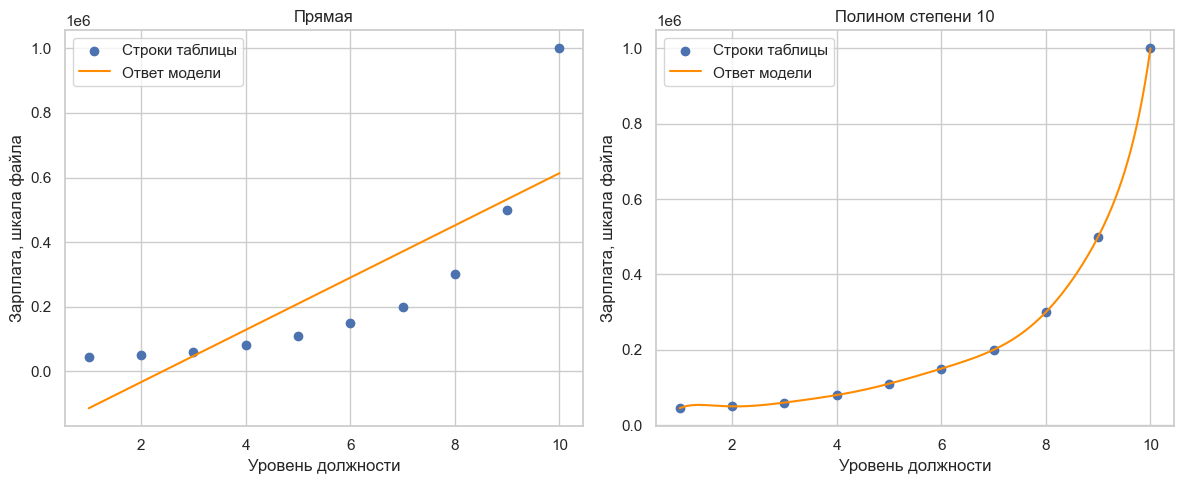

In [12]:
grid = pd.DataFrame({'Level': np.linspace(1, 10, 500)})
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, model, title in zip(axes, [linear_example, polynomial_example], ['Прямая', 'Полином степени 10']):
    ax.scatter(Xp.Level, yp, label='Строки таблицы')
    ax.plot(grid.Level, model.predict(grid), color='darkorange', label='Ответ модели')
    ax.set(title=title, xlabel='Уровень должности', ylabel='Зарплата, шкала файла')
    ax.legend()
fig.tight_layout()
save_show(fig, '01_positions_linear_polynomial.png')

Прямая передаёт общий рост, полином может точнее пройти через обучающие точки. Линии построены по отсортированной сетке, а не соединением строк в произвольном порядке. На таких данных совпадение с десятью известными зарплатами не проверяет качество между уровнями.

Сравниваем степени 2, 3, 6 и 15 из методички.

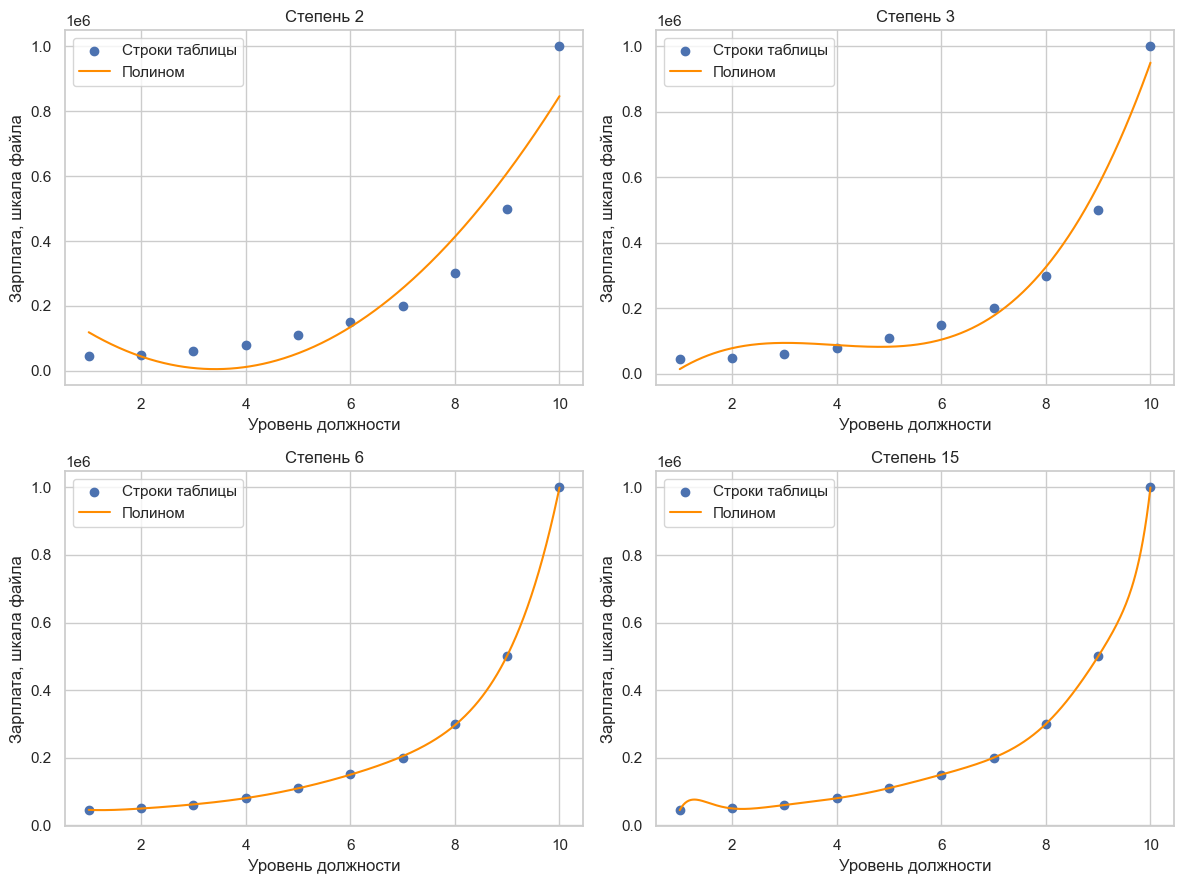

In [13]:
example_degrees = [2, 3, 6, 15]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, degree in zip(axes.flat, example_degrees):
    model = polynomial_pipeline(degree).fit(Xp, yp)
    ax.scatter(Xp.Level, yp, label='Строки таблицы')
    ax.plot(grid.Level, model.predict(grid), color='darkorange', label='Полином')
    ax.set(title=f'Степень {degree}', xlabel='Уровень должности', ylabel='Зарплата, шкала файла')
    ax.legend()
fig.tight_layout()
save_show(fig, '02_positions_degrees.png')

Квадратичная и кубическая кривые проще; степень 6 допускает больше изгибов. У степени 15 уже 16 параметров со свободным членом на 10 строках: решение не определяется однозначно данными. Даже ровное прохождение через точки не делает такую модель надёжной для новых уровней.

## 3. Индивидуальное задание: память по CPU

### 3.1. Прежний сценарий RCAEval
Работаем с тем же CPU-экспериментом Online Boutique. Каждая строка исходной таблицы — один момент наблюдения; числовые столбцы — метрики сервисов. Исходный файл не изменяем.


Читаем сохранённое имя сценария.

In [14]:
selection = json.loads((ROOT / 'reports/lab01/selected_case.json').read_text(encoding='utf-8'))
case = selection['case']
case_dir = ROOT / 'data/raw/rcaeval' / case

Загружаем локальные метрики и время внесения сбоя.

In [15]:
metrics_path = case_dir / 'metrics.parquet'
inject_path = case_dir / 'inject_time.txt'
df = pd.read_parquet(metrics_path)
inject_time = int(inject_path.read_text(encoding='utf-8').strip())

Показываем первые строки и размер данных.

In [16]:
display(df.head())
print('Сценарий:', case, '| Строк:', len(df), '| Метрик:', df.shape[1] - 1)
print('Пропусков:', int(df.isna().sum().sum()))

,time,adservice_cpu,cartservice_cpu,checkoutservice_cpu,currencyservice_cpu,emailservice_cpu,frontend_cpu,paymentservice_cpu,productcatalogservice_cpu,recommendationservice_cpu,...,adservice_latency-90,cartservice_latency-90,checkoutservice_latency-90,currencyservice_latency-90,emailservice_latency-90,frontend_latency-90,paymentservice_latency-90,productcatalogservice_latency-90,recommendationservice_latency-90,shippingservice_latency-90
0,1705353846,0.685023,2.216467,0.215886,19.035876,0.279166,6.724489,0.52931,2.636831,2.474853,...,0.004604,0.004993,0.850000,0.110638,0.0046,0.819737,0.008955,0.004418,0.009670,0.004576
1,1705353847,0.685023,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.636858,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008955,0.004423,0.009672,0.004576
2,1705353848,0.582707,2.216467,0.380058,19.035876,0.279166,6.724489,0.52931,2.584059,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.823697,0.008636,0.004423,0.009672,0.004576
3,1705353849,0.625903,2.216467,0.380058,19.106596,0.279166,6.724489,0.52931,3.250317,2.474853,...,0.004594,0.006015,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576
4,1705353850,0.613414,2.216467,0.380058,19.106596,0.279166,5.572668,0.52931,3.250317,2.474853,...,0.004594,0.006304,0.899999,0.099482,0.0046,0.814381,0.008636,0.004416,0.009672,0.004576


Сценарий: re2ob_checkoutservice_cpu_1 | Строк: 1441 | Метрик: 72
Пропусков: 4


Откладываем целые минутные участки для итоговой проверки.

In [17]:
groups = ((df.time - df.time.min()) // 60).astype(int)
period = (df.time >= inject_time).astype(int)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer_cv.split(df, period, groups))
groups_train = groups.iloc[train_idx]
print('Обучение и подбор:', len(train_idx), '| Итоговая проверка:', len(test_idx))

Обучение и подбор: 1141 | Итоговая проверка: 300


Соседние измерения похожи. При подборе и итоговой проверке записи одной минуты сохраняются вместе. Время и метка периода используются для разделения, а не как входные признаки модели. Все результаты относятся к одному эксперименту.

Выбираем тот же числовой ответ, что в работе № 8.

In [18]:
feature, target = 'checkoutservice_cpu', 'checkoutservice_mem'
X, y = df[[feature]].copy(), df[target] / 1e6
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
display(df[[feature, target]].isna().sum().rename('Пропуски'))

checkoutservice_cpu    0
checkoutservice_mem    0
Name: Пропуски, dtype: int64

Оцениваем текущую память по CPU того же момента. Деление памяти на миллион подписано явно: это миллионы исходных единиц, а не автоматически МБ. Память не входит в X. В двух выбранных столбцах пропусков нет; шаг заполнения остаётся в шаблоне.

### 3.2. Выбор степени только по обучению

Вычисляем ошибку пятичастной CV для разных степеней.

In [19]:
DEGREES = [1, 2, 3, 4, 6, 8, 10, 15]
cv = GroupKFold(n_splits=5)
degree_rows = []
for degree in DEGREES:
    scores = -cross_val_score(polynomial_pipeline(degree), X_train, y_train,
                              groups=groups_train, cv=cv, scoring='neg_mean_squared_error')
    degree_rows.append({'degree': degree, 'CV_MSE': scores.mean(), 'std': scores.std()})
degree_table = pd.DataFrame(degree_rows)
display(degree_table)

,degree,CV_MSE,std
0,1,0.355604,0.276804
1,2,0.108057,0.077521
2,3,0.095677,0.056577
3,4,0.155187,0.163002
4,6,0.103023,0.086067
5,8,0.114927,0.112453
6,10,0.538276,0.946810
7,15,96.102070,192.066067


Строим график ошибки CV при изменении степени.

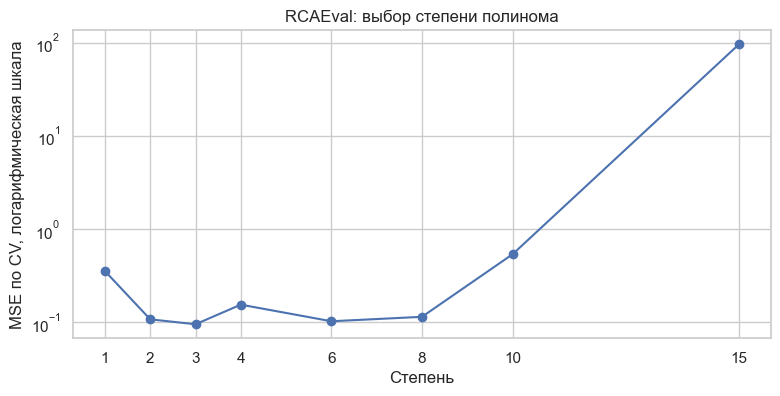

In [20]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(degree_table.degree, degree_table.CV_MSE, marker='o')
ax.set(title='RCAEval: выбор степени полинома', xlabel='Степень', ylabel='MSE по CV, логарифмическая шкала',
       xticks=DEGREES)
save_show(fig, '03_rca_degree_cv.png')

Низкая точка означает меньшую проверочную ошибку. Вертикальная шкала логарифмическая, чтобы видеть и небольшие, и большие ошибки. Степень выбираем по минимальной средней MSE; при равенстве берём меньшую. Все преобразования заново обучаются внутри каждой части CV.

Обучаем модели разных степеней и фиксируем выбранную.

In [21]:
best_degree = int(degree_table.loc[degree_table.CV_MSE.idxmin(), 'degree'])
models = {degree: polynomial_pipeline(degree).fit(X_train, y_train) for degree in DEGREES}
model = models[best_degree]
print('Выбрана степень:', best_degree)

Выбрана степень: 3


Показываем кривые для степеней 1, 2, 3 и 15.

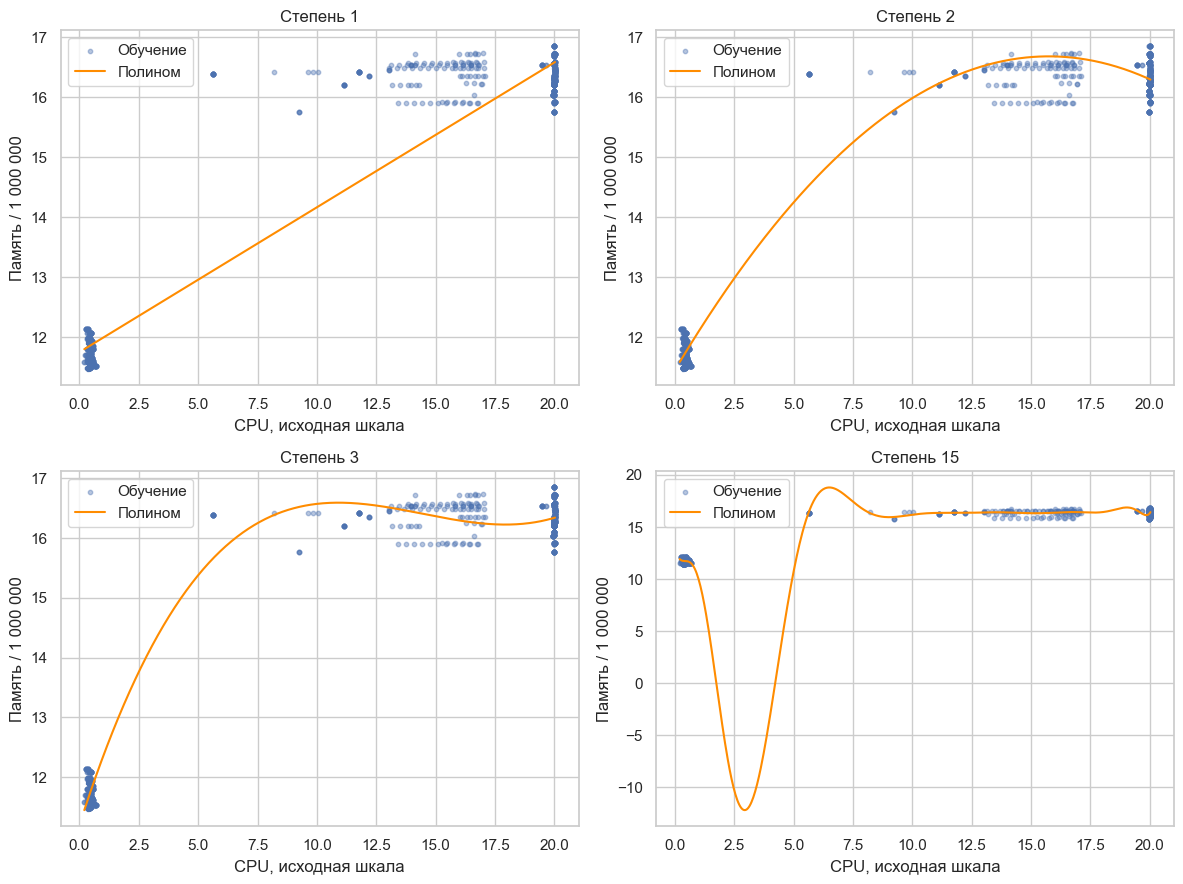

In [22]:
rca_grid = pd.DataFrame({feature: np.linspace(X_train[feature].min(), X_train[feature].max(), 500)})
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, degree in zip(axes.flat, [1, 2, 3, 15]):
    ax.scatter(X_train[feature], y_train, s=10, alpha=0.4, label='Обучение')
    ax.plot(rca_grid[feature], models[degree].predict(rca_grid), color='darkorange', label='Полином')
    ax.set(title=f'Степень {degree}', xlabel='CPU, исходная шкала', ylabel='Память / 1 000 000')
    ax.legend()
fig.tight_layout()
save_show(fig, '04_rca_degrees.png')

Точки — настоящие обучающие измерения, линия — ответы модели. Между низким и высоким CPU мало наблюдений, поэтому там возможны большие изгибы. Разные панели могут иметь разные вертикальные шкалы. Сильный изгиб в пустом промежутке — поведение модели, а не измеренный скачок памяти.

Проверяем выбранный полином, прямую и средний baseline на отложенных минутах.

In [23]:
prediction = model.predict(X_test)
linear_prediction = models[1].predict(X_test)
mean_prediction = np.full(len(y_test), y_train.mean())
metrics = pd.DataFrame([regression_scores(y_test, mean_prediction), regression_scores(y_test, linear_prediction),
                       regression_scores(y_test, prediction)], index=['Среднее обучения', 'Прямая', 'Выбранный полином'])
display(metrics)

,MSE,MAE,R2
Среднее обучения,5.295515,2.289958,-0.063386
Прямая,0.091665,0.256717,0.981593
Выбранный полином,0.042931,0.180311,0.991379


MSE и MAE меньше у более точного результата. MAE выражена в миллионах исходных единиц памяти. Выбранная степень не меняется по этой таблице: это итоговая проверка, которая не участвовала в подборе.

Строим выбранную кривую с отложенными точками.

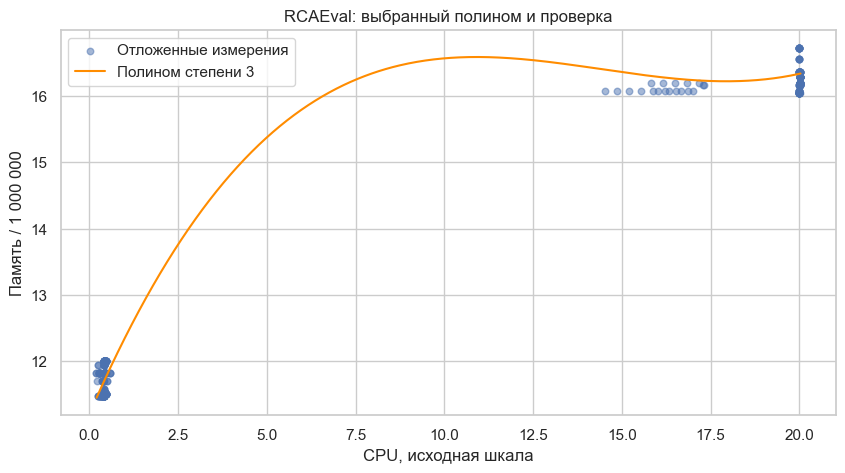

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(X_test[feature], y_test, s=22, alpha=0.5, label='Отложенные измерения')
ax.plot(rca_grid[feature], model.predict(rca_grid), color='darkorange', label=f'Полином степени {best_degree}')
ax.set(title='RCAEval: выбранный полином и проверка', xlabel='CPU, исходная шкала', ylabel='Память / 1 000 000')
ax.legend()
save_show(fig, '05_rca_selected.png')

Линия обучена по другим минутам, точки — итоговая проверка. Вертикальное отклонение показывает ошибку. Даже при хороших ответах на этих двух режимах нельзя по одному эксперименту гарантировать качество во всём диапазоне CPU.

### 3.3. Дополнительная строка задач про модификации kNN
В списке задач методички также указан kNN. Для её выполнения отдельно сравниваем kNN-регрессию с равными весами соседей и с весами по расстоянию. Это дополнительный опыт, который не заменяет полиномиальную модель.

Сравниваем два варианта kNN по тем же частям CV.

In [25]:
knn_rows = []
for weights in ['uniform', 'distance']:
    knn = Pipeline([('scale', StandardScaler()), ('regression', KNeighborsRegressor(n_neighbors=5, weights=weights))])
    scores = -cross_val_score(knn, X_train, y_train, groups=groups_train, cv=cv, scoring='neg_mean_squared_error')
    knn_rows.append({'weights': weights, 'CV_MSE': scores.mean()})
display(pd.DataFrame(knn_rows))

,weights,CV_MSE
0,uniform,0.145160
1,distance,0.130559


Обычный вариант усредняет ответы пяти соседей одинаково; взвешенный сильнее учитывает близкие точки. Результаты относятся к этому разбиению и не служат выбором степени полинома.

Сохраняем ответы, параметры и простой текст результата.

In [26]:
answers = pd.DataFrame({'row': X_test.index, 'time': df.time.iloc[test_idx].to_numpy(),
                        'actual': y_test.to_numpy(), 'prediction': prediction})
answers.to_csv(REPORT / 'predictions.csv', index=False)
degree_table.to_csv(REPORT / 'degree_cv.csv', index=False)
metrics.to_csv(REPORT / 'regression_metrics.csv', index_label='model')
pd.DataFrame(knn_rows).to_csv(REPORT / 'knn_cv.csv', index=False)
analysis = (f'Применил общий пайплайн к полиномиальной регрессии на {case}. Проверил степени {DEGREES}; '
            f'по пяти частям CV выбрана степень {best_degree}. '
            f'На {len(y_test)} отложенных строках MAE = {mean_absolute_error(y_test, prediction):.4f} в миллионах исходных единиц памяти. '
            'Графики показали изменение формы кривой и опасность изгибов между редкими наблюдениями. '
            'Дополнительно сравнил два способа усреднения соседей kNN. Результат относится к текущей памяти одного эксперимента.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
summary = {'case': case, 'degrees': DEGREES, 'best_degree': best_degree, 'test_rows': len(y_test),
           'regression': regression_scores(y_test, prediction), 'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
sources = {'example_url': example_url, 'rcaeval': selection,
           'sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in [example_path, metrics_path, inject_path]}}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Применил общий пайплайн к полиномиальной регрессии на re2ob_checkoutservice_cpu_1. Проверил степени [1, 2, 3, 4, 6, 8, 10, 15]; по пяти частям CV выбрана степень 3. На 300 отложенных строках MAE = 0.1803 в миллионах исходных единиц памяти. Графики показали изменение формы кривой и опасность изгибов между редкими наблюдениями. Дополнительно сравнил два способа усреднения соседей kNN. Результат относится к текущей памяти одного эксперимента.

1143

## 4. Заключение
Научился применять разработанный пайплайн для тиражирования кода и решения задачи полиномиальной регрессии. Освоил PolynomialFeatures, сравнение степеней и выбор модели по обучающей CV.

На примере изучил зависимость зарплаты от уровня должности, на RCAEval — текущей памяти от CPU. Увидел, что увеличение степени меняет изгибы и не гарантирует уменьшения ошибок. Дополнительно сравнил модификации kNN, указанные в задачах методички.



## 5. Ответы на контрольные вопросы
**1. Зачем признак из единиц?**  
Он задаёт свободный член. В statsmodels OLS его обычно добавляют явно; LinearRegression уже обучает свободный член по умолчанию. Поэтому в PolynomialFeatures здесь задано `include_bias=False`.

**2. Что такое фиктивная переменная и почему удаляют одну?**  
Это признак 0/1, показывающий категорию. Все индикаторы одной категории вместе со свободным членом линейно зависимы: их сумма равна единице. Один индикатор оставляют базовым.

**3. Какой класс создаёт полиномиальную регрессию?**  
`PolynomialFeatures` создаёт новые признаки, а `LinearRegression` обучает их веса. Вместе они образуют модель в Pipeline.

**4. Как преобразуются признаки?**  
Для одного входа x добавляются x², x³ и далее до выбранной степени. Для нескольких входов добавляются также их произведения. Число столбцов растёт, поэтому высокая степень быстро усложняет модель.

**5. Можно ли масштабировать признаки?**  
Да. Здесь вход приводится к −1…1 до возведения в степени, чтобы избежать огромных чисел. Параметры масштаба получают по обучению и сохраняют для новых строк.
